# 📄 Reporte Analítico de Calidad de Datos (Modelo Hedónico)
Este cuaderno analiza la calidad de la extracción de datos inmobiliarios desde redes sociales, evaluando tanto la muestra aceptada (Capa Silver) como los registros descartados para justificar metodológicamente el filtro.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown

# 🎨 1. CONFIGURACIÓN DE DISEÑO EXPERTO (ESTÁNDARES DE PRESENTACIÓN)
sns.set_theme(style="white", context="notebook", font_scale=1.1)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Paleta corporativa semántica
COLOR_FB = '#1877F2'   # Azul Facebook
COLOR_TK = '#202020'   # Oscuro TikTok
COLOR_ACEPTADO = '#2E7D32' # Verde Esmeralda
COLOR_DESCARTADO = '#D32F2F' # Rojo Carmesí
palette_redes = {'Facebook': COLOR_FB, 'TikTok': COLOR_TK}

# 📁 2. CARGA DE DATOS
BASE_DIR = Path().resolve().parent
RUTA_SILVER = BASE_DIR / "data" / "interim" / "social_clean" / "alquileres_social_silver.csv"
RUTA_DESCARTADOS = BASE_DIR / "data" / "interim" / "social_clean" / "alquileres_social_descartados.csv"

df_s = pd.read_csv(RUTA_SILVER, low_memory=False) if RUTA_SILVER.exists() else pd.DataFrame()
df_d = pd.read_csv(RUTA_DESCARTADOS, low_memory=False) if RUTA_DESCARTADOS.exists() else pd.DataFrame()

# Limpieza de nombres de portales para los gráficos
if not df_s.empty: 
    df_s['portal_clean'] = df_s['portal'].replace({'facebook_marketplace': 'Facebook', 'tiktok': 'TikTok', 'facebook': 'Facebook'})
if not df_d.empty:
    df_d['portal_clean'] = df_d['portal'].replace({'facebook_marketplace': 'Facebook', 'tiktok': 'TikTok', 'facebook': 'Facebook'})

print("✅ Entorno visual configurado y bases de datos cargadas exitosamente.")

✅ Entorno visual configurado y bases de datos cargadas exitosamente.


##  funnel 1. Embudo de Retención General y por Plataforma
¿Cuánta información cruda se recolectó y cuánta sobrevivió a nuestras estrictas reglas de negocio e IA? Aquí analizamos la eficiencia de la extracción segmentada por red social.

### 📈 Métricas Globales

- **Total Bruto Extraído:** 3,928 anuncios

- **✅ Retención (Silver):** 2,495 anuncios (63.5%)

- **❌ Exclusión:** 1,433 anuncios (36.5%)

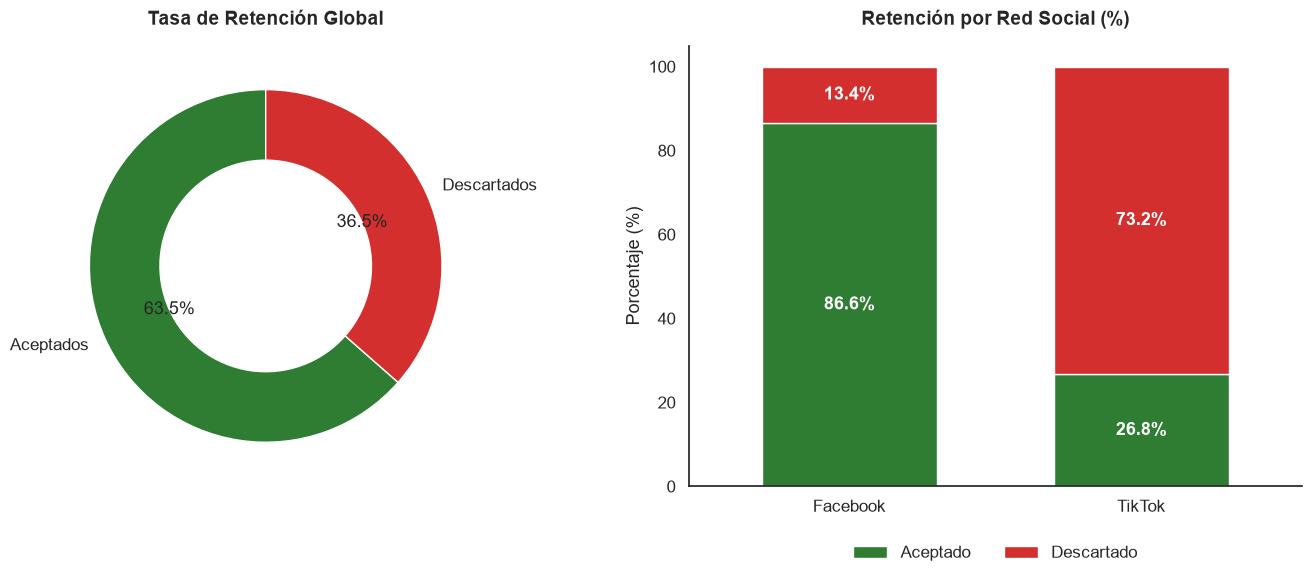

### 📋 Detalle Absoluto por Plataforma

Estado,Total Extraído,Aceptado,Descartado,Tasa de Aceptación
portal_clean,,,,
Facebook,2414,2090,324,86.6%
TikTok,1514,405,1109,26.8%


In [2]:
total_silver = len(df_s)
total_descartados = len(df_d)
total_bruto = total_silver + total_descartados

if total_bruto > 0:
    # Preparar dataframe unificado para cálculos
    df_s_temp = df_s[['portal_clean']].assign(Estado='Aceptado') if total_silver > 0 else pd.DataFrame()
    df_d_temp = df_d[['portal_clean']].assign(Estado='Descartado') if total_descartados > 0 else pd.DataFrame()
    df_all = pd.concat([df_s_temp, df_d_temp])
    
    # 1.1 Kpis de texto
    display(Markdown(f"### 📈 Métricas Globales"))
    display(Markdown(f"- **Total Bruto Extraído:** {total_bruto:,} anuncios"))
    display(Markdown(f"- **✅ Retención (Silver):** {total_silver:,} anuncios ({(total_silver/total_bruto)*100:.1f}%)"))
    display(Markdown(f"- **❌ Exclusión:** {total_descartados:,} anuncios ({(total_descartados/total_bruto)*100:.1f}%)"))

    # 1.2 Gráficos de Embudo
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Gráfico A: Donut General
    axes[0].pie([total_silver, total_descartados], labels=['Aceptados', 'Descartados'], 
                autopct='%1.1f%%', startangle=90, colors=[COLOR_ACEPTADO, COLOR_DESCARTADO],
                wedgeprops=dict(width=0.4, edgecolor='w'))
    axes[0].set_title('Tasa de Retención Global', fontsize=14, fontweight='bold', pad=15)

    # Gráfico B: Retención por Red Social (Barras Apiladas 100%)
    crosstab_portal = pd.crosstab(df_all['portal_clean'], df_all['Estado'], normalize='index') * 100
    crosstab_counts = pd.crosstab(df_all['portal_clean'], df_all['Estado'])
    
    crosstab_portal = crosstab_portal[['Aceptado', 'Descartado']] # Ordenar
    ax2 = crosstab_portal.plot(kind='bar', stacked=True, ax=axes[1], color=[COLOR_ACEPTADO, COLOR_DESCARTADO], width=0.6)
    
    axes[1].set_title('Retención por Red Social (%)', fontsize=14, fontweight='bold', pad=15)
    axes[1].set_xlabel('')
    axes[1].set_ylabel('Porcentaje (%)')
    axes[1].tick_params(axis='x', rotation=0)
    axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
    
    # Agregar Data Labels (Porcentajes exactos en las barras)
    for c in ax2.containers:
        ax2.bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')
        
    plt.tight_layout()
    plt.show()
    
    # Tabla resumen por plataforma
    display(Markdown(f"### 📋 Detalle Absoluto por Plataforma"))
    resumen_portal = crosstab_counts.copy()
    resumen_portal['Total Extraído'] = resumen_portal.sum(axis=1)
    resumen_portal['Tasa de Aceptación'] = (resumen_portal['Aceptado'] / resumen_portal['Total Extraído'] * 100).round(1).astype(str) + '%'
    display(resumen_portal[['Total Extraído', 'Aceptado', 'Descartado', 'Tasa de Aceptación']])

else:
    print("⚠️ No hay datos para analizar el embudo.")

## 🗑️ 2. Análisis de Datos Descartados
Detalle de las reglas metodológicas que provocaron la eliminación de anuncios de la muestra.

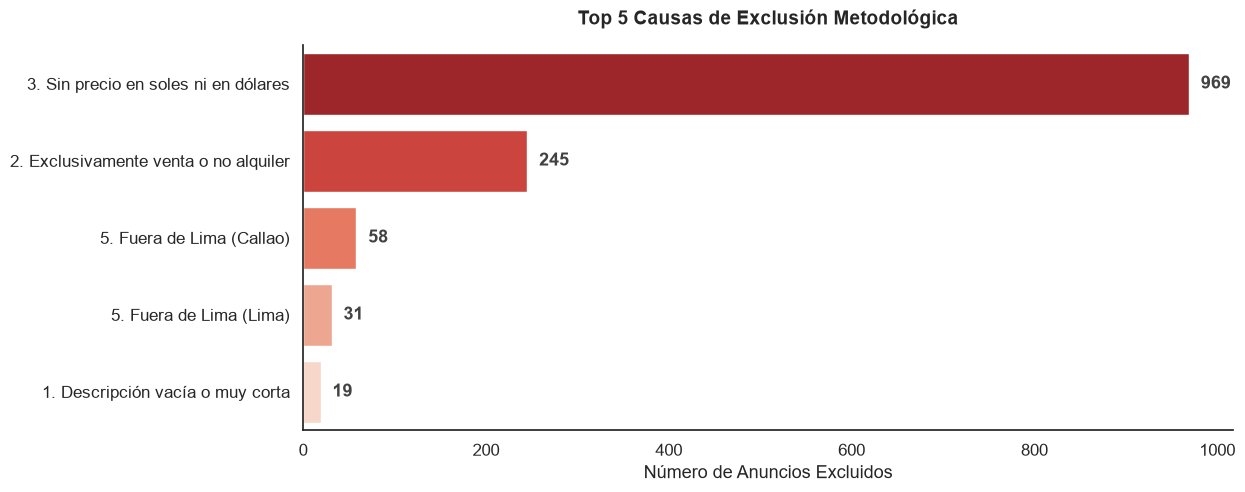

**Detalle tabular completo de todas las exclusiones:**

,Causa de Exclusión,Volumen,% del Descarte
0,3. Sin precio en soles ni en dólares,969,67.6
1,2. Exclusivamente venta o no alquiler,245,17.1
2,5. Fuera de Lima (Callao),58,4.0
3,5. Fuera de Lima (Lima),31,2.2
4,1. Descripción vacía o muy corta,19,1.3
5,4. Sin dirección ni distrito en descripción,16,1.1
6,5. Fuera de Lima (La Perla),16,1.1
7,5. Fuera de Lima (Bellavista),16,1.1
8,5. Fuera de Lima (Ventanilla),10,0.7
9,5. Fuera de Lima (None),10,0.7


In [6]:
if total_descartados > 0:
    motivos = df_d['motivo_descarte'].value_counts().reset_index()
    motivos.columns = ['Causa de Exclusión', 'Volumen']
    motivos['% del Descarte'] = (motivos['Volumen'] / total_descartados * 100).round(1)
    
    # 🎨 DISEÑO EXPERTO: Filtramos solo el Top 5 para el gráfico y evitamos el amontonamiento visual
    top_motivos = motivos.head(5)
    
    fig, ax = plt.subplots(figsize=(12, 5))
    # Solucionado el warning de Seaborn añadiendo hue='Causa de Exclusión' y legend=False
    sns.barplot(data=top_motivos, x='Volumen', y='Causa de Exclusión', hue='Causa de Exclusión', palette="Reds_r", legend=False, ax=ax)
    
    ax.set_title('Top 5 Causas de Exclusión Metodológica', fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('Número de Anuncios Excluidos')
    ax.set_ylabel('')
    
    # Data Labels elegantes
    for container in ax.containers:
        ax.bar_label(container, fmt=' %d', padding=5, fontweight='bold', color='#424242')
        
    sns.despine()
    plt.show()
    
    display(Markdown("**Detalle tabular completo de todas las exclusiones:**"))
    display(motivos)
else:
    print("No hay datos descartados registrados.")

## 💎 3. Perfil de la Muestra Aceptada (Capa Silver)
Análisis descriptivo de los registros limpios, con distritos validados y listos para el modelado hedónico.

### 🏢 Composición del Portafolio: Plataforma vs. Tipo de Vivienda

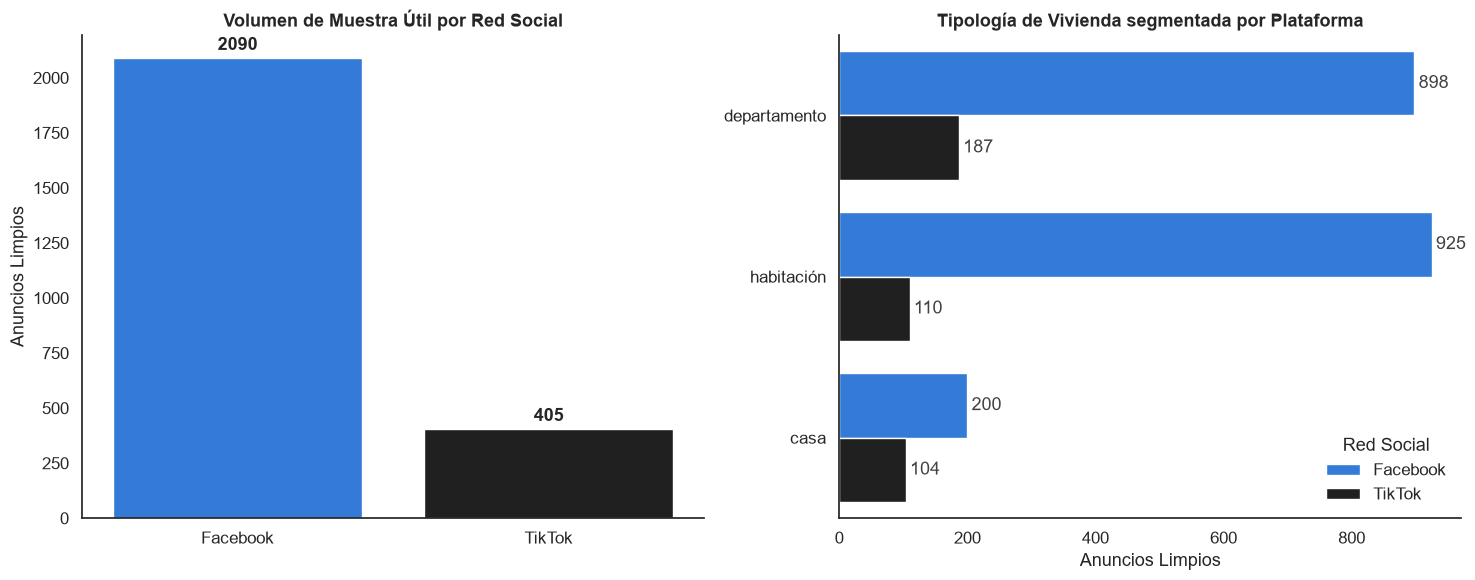

portal_clean,Facebook,TikTok,TOTAL
tipo_inmueble,,,
Casa,200,104,304
Departamento,898,187,1085
Habitación,925,110,1035
TOTAL,2023,401,2424


In [7]:
if total_silver > 0:
    # 3.1 Composición por Red Social y Tipo de Inmueble
    display(Markdown("### 🏢 Composición del Portafolio: Plataforma vs. Tipo de Vivienda"))
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Gráfico A: Solucionado el FutureWarning (hue asignado a la misma variable de x)
    ax_redes = sns.countplot(data=df_s, x='portal_clean', hue='portal_clean', legend=False, 
                             palette=palette_redes, ax=axes[0], order=df_s['portal_clean'].value_counts().index)
    
    axes[0].set_title('Volumen de Muestra Útil por Red Social', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('')
    axes[0].set_ylabel('Anuncios Limpios')
    for c in ax_redes.containers:
        axes[0].bar_label(c, fmt='%d', padding=3, fontweight='bold')

    # Gráfico B: Tipología segmentada
    ax_tipo = sns.countplot(data=df_s, y='tipo_inmueble', hue='portal_clean', palette=palette_redes, 
                            ax=axes[1], order=df_s['tipo_inmueble'].value_counts().index)
    
    axes[1].set_title('Tipología de Vivienda segmentada por Plataforma', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Anuncios Limpios')
    axes[1].set_ylabel('')
    axes[1].legend(title='Red Social', loc='lower right', frameon=False)
    for c in ax_tipo.containers:
        axes[1].bar_label(c, fmt='%d', padding=3, color='#424242')

    sns.despine()
    plt.tight_layout()
    plt.show()
    
    # Tabla cruzada
    tabla_cruzada = pd.crosstab(df_s['tipo_inmueble'].str.capitalize(), df_s['portal_clean'], margins=True, margins_name="TOTAL")
    display(tabla_cruzada)

### 💰 3.2 Análisis Financiero Descriptivo
Distribución de los precios de alquiler (en Soles) extraídos, comparando el comportamiento económico entre Facebook y TikTok para detectar posibles sesgos de mercado.

### 💰 3.2 Resumen Financiero Descriptivo por Tipología

Distribución de los precios de alquiler (en Soles) extraídos, segmentados por **Tipo de Inmueble** y comparados entre **Facebook y TikTok** para detectar sesgos de mercado (outliers).

,Muestra Limpia,Precio Promedio (S/),Precio Mediana (S/)
tipo_inmueble,,,
casa,276,22206.43,1300.0
departamento,1059,4266.36,1600.0
habitación,1034,650.65,597.5


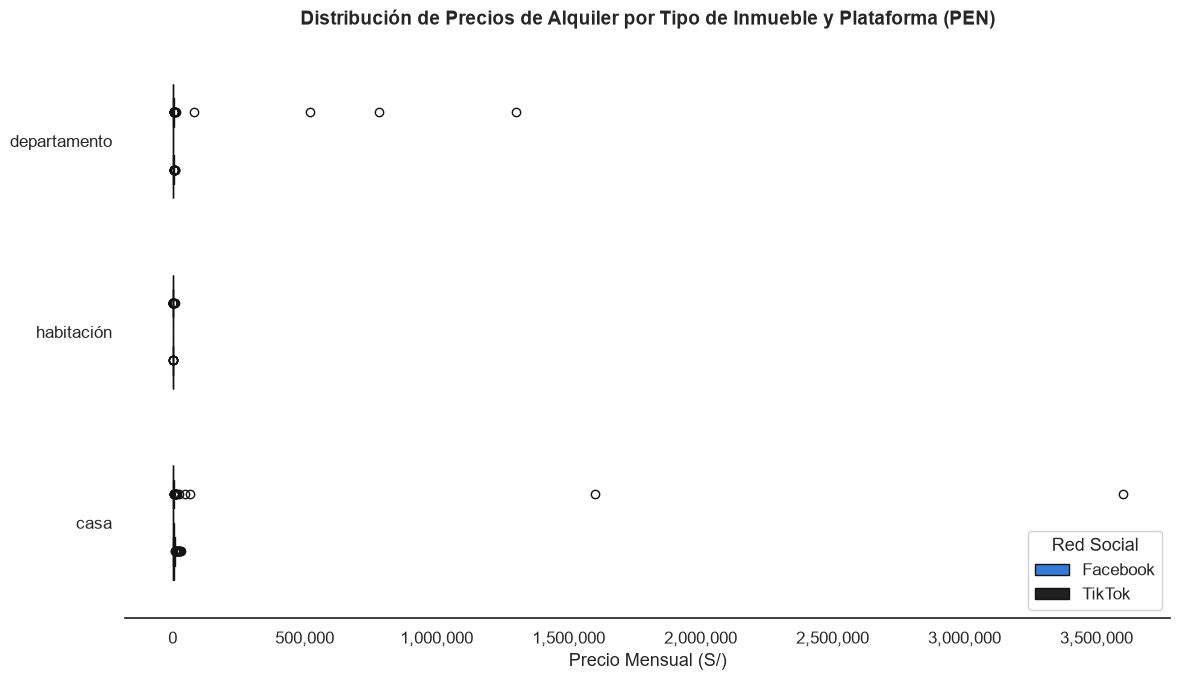

In [9]:
if total_silver > 0:
    df_s['precio_pen_num'] = pd.to_numeric(df_s['precio_pen'], errors='coerce')
    
    # Filtramos nulos de precio y de tipo de inmueble para un cruce exacto
    df_precios = df_s.dropna(subset=['precio_pen_num', 'tipo_inmueble'])
    
    if not df_precios.empty:
        display(Markdown("### 💰 3.2 Resumen Financiero Descriptivo por Tipología"))
        display(Markdown("Distribución de los precios de alquiler (en Soles) extraídos, segmentados por **Tipo de Inmueble** y comparados entre **Facebook y TikTok** para detectar sesgos de mercado (outliers)."))
        
        # 1. Tabla Estadística Financiera
        resumen_fin = df_precios.groupby('tipo_inmueble')['precio_pen_num'].agg(['count', 'mean', 'median']).round(2)
        resumen_fin.columns = ['Muestra Limpia', 'Precio Promedio (S/)', 'Precio Mediana (S/)']
        display(resumen_fin.sort_values('Precio Promedio (S/)', ascending=False))
        
        # 2. Gráfico de Cajas (Boxplot) Multidimensional
        fig, ax = plt.subplots(figsize=(12, 7))
        
        # Ordenamos los ejes Y desde el que tiene más observaciones hasta el que tiene menos
        orden_tipos = df_precios['tipo_inmueble'].value_counts().index
        
        sns.boxplot(data=df_precios, x='precio_pen_num', y='tipo_inmueble', hue='portal_clean', 
                    palette=palette_redes, ax=ax, width=0.6, order=orden_tipos)
        
        ax.set_title('Distribución de Precios de Alquiler por Tipo de Inmueble y Plataforma (PEN)', fontsize=14, fontweight='bold', pad=15)
        ax.set_xlabel('Precio Mensual (S/)')
        ax.set_ylabel('')
        ax.legend(title='Red Social', loc='lower right', framealpha=0.9)
        
        # Formatear el eje X con separadores de miles para lectura financiera
        ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
        
        sns.despine(left=True)
        plt.tight_layout()
        plt.show()
    else:
        print("No hay precios numéricos válidos en soles para analizar.")